# MNR UNIVERSITY
### School of Engineering, Technology & Artificial Intelligence
## Machine Learning Mini Project (25CSM201) — 2nd Year, 1st Semester
---
# AI Based Student Skill Gap Analysis and Career Recommendation System
**An End-to-End Supervised Multi-Class Classification & Skill Gap Benchmarking Framework**

- **Team Members:**
  1. ***K.Tanmai sree***,25RBAIM0049 (Section: A)
  2. **Uzma begum** — Roll No: `25RBAIM0019` (Section: A)
  3. ***Swetha**_Roll No: '25RBAIM0050' (Section: A)
- **Branch:** B. Tech (Hons.) / CSE (AI & ML)
- **Course Name:** Machine Learning (Course Code: `25CSM201`)
- **Project Guide:** Dr. M. Praveen
- **Experiment:** Experiment 30 — End-to-End Machine Learning Solution using a Real-World Dataset
---

## 1. Project Overview & Problem Statement

Engineering and computer science students frequently experience ambiguity regarding their alignment with industry job roles and difficulty identifying specific technical deficiencies. Rapid evolutions in Artificial Intelligence, Cloud Computing, Cybersecurity, and Software Engineering create a widening gap between academic curricula and industrial expectations.

### Primary Objectives:
1. Ingest and audit a multifaceted student dataset comprising **2,400 student profiles** across **16 academic, competitive coding, and practical project variables**.
2. Benchmark **six supervised classification algorithms** to predict optimal career specialization tracks:
   - Logistic Regression (Multinomial with L2 Regularization)
   - Support Vector Machine (RBF Kernel)
   - Random Forest Classifier (100 Ensemble Trees)
   - Gaussian Naive Bayes (Probabilistic)
   - K-Nearest Neighbors (Standardized Euclidean Metric)
   - Decision Tree Classifier (Gini Impurity Splitting)
3. Evaluate models via **5-Fold Stratified Cross-Validation**, Accuracy, Weighted Precision, Recall, F1-Score, and Multi-Class ROC-AUC (One-vs-Rest).
4. Engineer an **AI-driven Skill Gap Analysis Engine** that quantitatively benchmarks student proficiencies against top-quartile industry role competencies and outputs personalized remediation roadmaps.

In [4]:
# 2. Imports and Environment Setup
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, roc_curve
)

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 10
print("Environment and Machine Learning libraries successfully initialized!")

Environment and Machine Learning libraries successfully initialized!


## 3. Dataset Ingestion, Inspection & Auditing

In [5]:
# Load the dataset
dataset_path = 'student_skills_career_dataset.csv' if os.path.exists('student_skills_career_dataset.csv') else 'data/student_skills_career_dataset.csv'
df = pd.read_csv(dataset_path)

print(f"Dataset Dimensions : {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Total Missing / Null: {df.isnull().sum().sum()}")
df.head()

Dataset Dimensions : 2400 rows x 17 columns
Total Missing / Null: 0


,CGPA,Programming_Proficiency,DSA_Score,Operating_Systems_Score,Computer_Networks_Score,Database_Systems_Score,Machine_Learning_Score,Web_Development_Score,Cloud_Computing_Score,Mathematics_Stats_Score,Coding_Contest_Rating,Hackathons_Count,Projects_Completed,Certifications_Count,Internship_Months,Soft_Skills_Rating,Recommended_Career
0,8.20,73.8,73.7,63.7,56.3,72.5,60.2,99.0,57.4,35.6,1457,4,1,1,0,7.3,Full Stack Web Developer
1,7.18,99.0,56.3,71.9,55.0,72.7,61.4,63.7,79.3,69.4,1616,6,2,3,0,6.4,Data Engineer & Database Architect
2,6.70,80.1,61.3,74.4,99.0,63.7,62.5,39.9,55.7,53.7,1504,4,1,3,0,8.2,Cybersecurity Analyst
3,7.14,99.0,46.1,63.3,57.4,99.0,62.5,59.4,48.4,71.4,1457,5,1,3,6,8.2,Data Engineer & Database Architect
4,6.91,77.5,73.8,67.1,70.5,73.3,58.6,96.7,67.3,54.2,1541,3,2,0,0,7.2,Full Stack Web Developer


## 4. Exploratory Data Analysis (EDA) & Competency Distributions

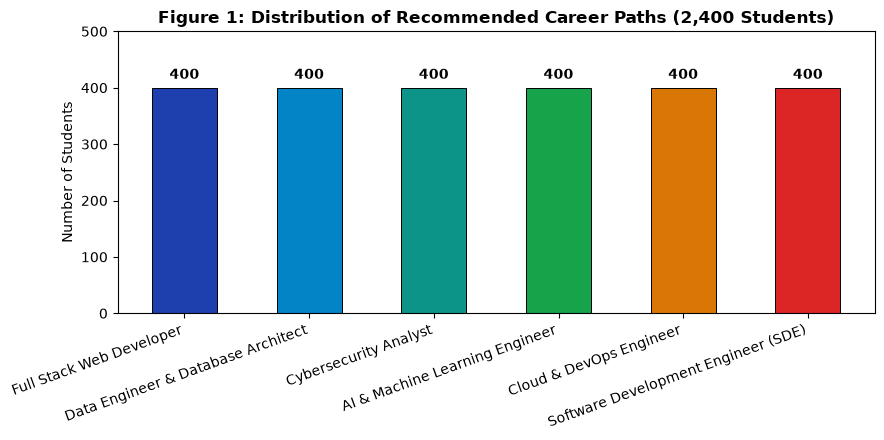

In [6]:
# Class Distribution of Career Specializations
plt.figure(figsize=(9, 4.5))
counts = df['Recommended_Career'].value_counts()
colors = ['#1e40af', '#0284c7', '#0d9488', '#16a34a', '#d97706', '#dc2626']
bars = plt.bar(counts.index, counts.values, color=colors, width=0.52, edgecolor='black', linewidth=0.7)
plt.title('Figure 1: Distribution of Recommended Career Paths (2,400 Students)', fontsize=12, fontweight='bold')
plt.ylabel('Number of Students')
plt.xticks(rotation=20, ha='right')
plt.ylim(0, 500)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 10, f'{yval}', ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()

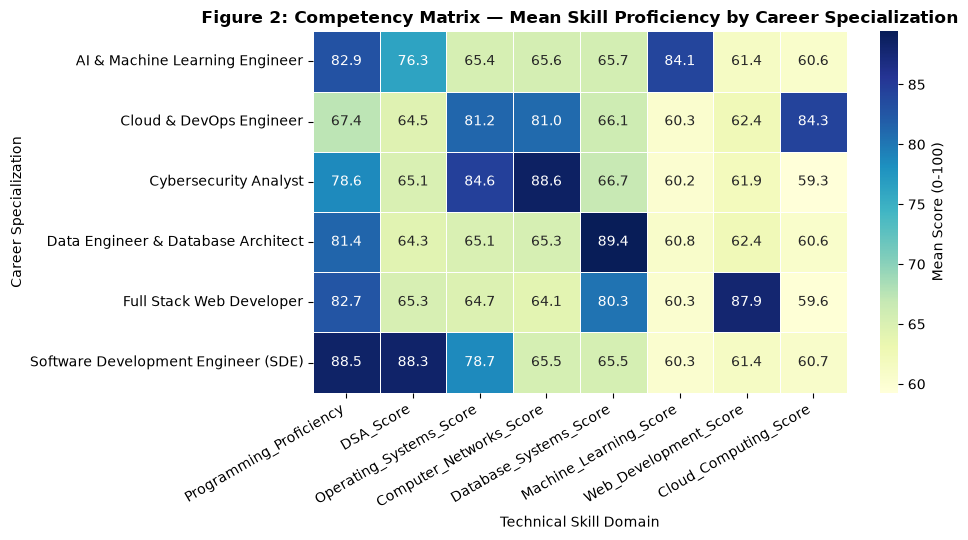

In [7]:
# Competency Matrix across Career Paths
skill_cols = ['Programming_Proficiency', 'DSA_Score', 'Operating_Systems_Score', 
              'Computer_Networks_Score', 'Database_Systems_Score', 'Machine_Learning_Score', 
              'Web_Development_Score', 'Cloud_Computing_Score']
mean_skills = df.groupby('Recommended_Career')[skill_cols].mean()

plt.figure(figsize=(10, 5.5))
sns.heatmap(mean_skills, cmap='YlGnBu', annot=True, fmt='.1f', linewidths=0.5, cbar_kws={'label': 'Mean Score (0-100)'})
plt.title('Figure 2: Competency Matrix — Mean Skill Proficiency by Career Specialization', fontsize=12, fontweight='bold')
plt.ylabel('Career Specialization')
plt.xlabel('Technical Skill Domain')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

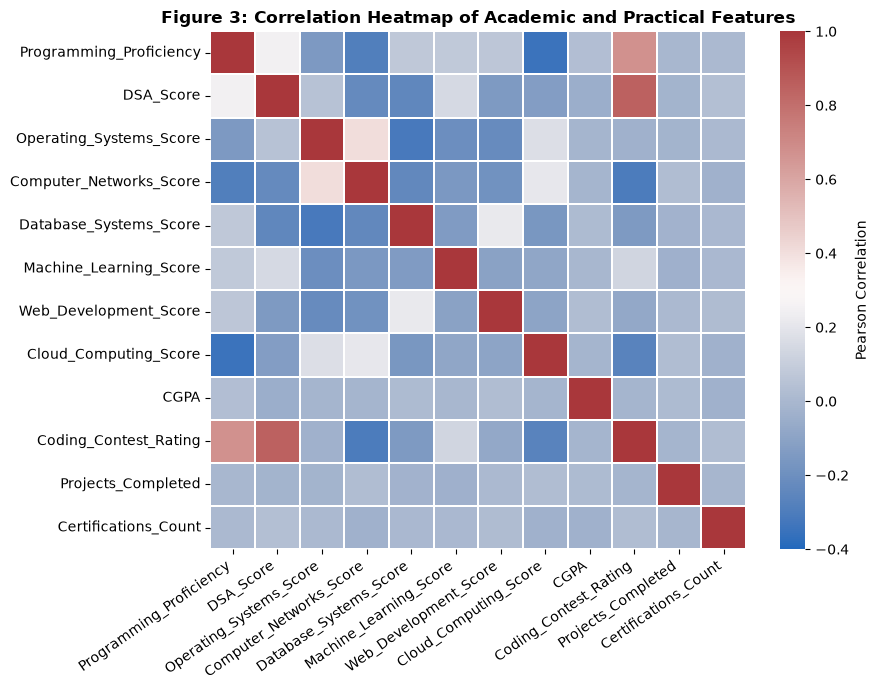

In [8]:
# Feature Correlation Heatmap
corr_cols = skill_cols + ['CGPA', 'Coding_Contest_Rating', 'Projects_Completed', 'Certifications_Count']
plt.figure(figsize=(9, 7))
corr = df[corr_cols].corr()
sns.heatmap(corr, cmap='vlag', vmin=-0.4, vmax=1.0, annot=False, linewidths=0.3, cbar_kws={'label': 'Pearson Correlation'})
plt.title('Figure 3: Correlation Heatmap of Academic and Practical Features', fontsize=12, fontweight='bold')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

## 5. Stratified Data Partitioning & Pipeline Construction

To ensure robust evaluation without data leakage, feature scaling via `StandardScaler` is encapsulated inside Scikit-learn `Pipeline` architectures. The dataset is partitioned into **80% training (1,920 records)** and **20% testing (480 records)** using stratified sampling.

In [9]:
X = df.drop(columns=['Recommended_Career'])
y = df['Recommended_Career']

le = LabelEncoder()
y_encoded = le.fit_transform(y)
class_names = le.classes_

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.20, random_state=42, stratify=y_encoded
)

print(f"Training Samples : {X_train.shape[0]} (80.0%)")
print(f"Testing Samples  : {X_test.shape[0]} (20.0%)")
print(f"Classes          : {len(class_names)} balanced target tracks (80 test records per track)")

Training Samples : 1920 (80.0%)
Testing Samples  : 480 (20.0%)
Classes          : 6 balanced target tracks (80 test records per track)


## 6. Supervised Classification Benchmarking & 5-Fold Stratified Cross-Validation

In [10]:
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Support Vector Machine': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVC(kernel='rbf', probability=True, random_state=42))
    ]),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gaussian Naive Bayes': GaussianNB(),
    'K-Nearest Neighbors': Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=5))
    ]),
    'Decision Tree': DecisionTreeClassifier(random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []
probs_dict = {}
preds_dict = {}

for name, model in models.items():
    cv_acc = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy').mean()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)

    preds_dict[name] = y_pred
    probs_dict[name] = y_prob

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    auc = roc_auc_score(y_test, y_prob, multi_class='ovr')

    results.append({
        'Model': name,
        'CV_Acc': cv_acc,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1': f1,
        'ROC_AUC': auc
    })

comparison_df = pd.DataFrame(results)
print("=" * 80)
print("MULTI-MODEL BENCHMARK RESULTS (20% HELD-OUT TEST DATA):")
print("=" * 80)
print(comparison_df.round(4).to_string(index=False))
print("=" * 80)

MULTI-MODEL BENCHMARK RESULTS (20% HELD-OUT TEST DATA):
                 Model  CV_Acc  Accuracy  Precision  Recall     F1  ROC_AUC
   Logistic Regression  0.9214    0.9229     0.9234  0.9229 0.9229   0.9931
Support Vector Machine  0.9068    0.9167     0.9173  0.9167 0.9163   0.9925
         Random Forest  0.9042    0.9125     0.9131  0.9125 0.9121   0.9880
  Gaussian Naive Bayes  0.9125    0.9229     0.9234  0.9229 0.9230   0.9915
   K-Nearest Neighbors  0.8891    0.8833     0.8832  0.8833 0.8826   0.9771
         Decision Tree  0.8099    0.8188     0.8183  0.8188 0.8181   0.8912


## 7. Model Performance Diagnostics & Evaluation Figures

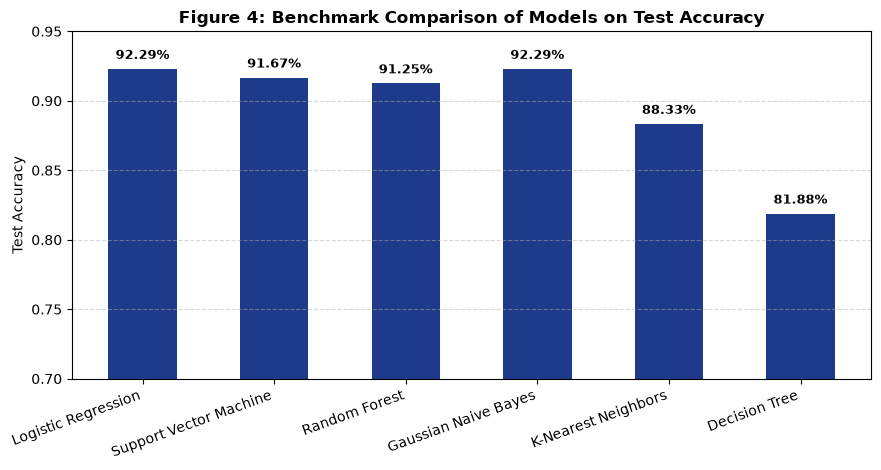

In [11]:
# Figure 4: Model Accuracy Comparison
plt.figure(figsize=(9, 4.8))
bars = plt.bar(comparison_df['Model'], comparison_df['Accuracy'], color='#1e3a8a', width=0.52)
plt.title('Figure 4: Benchmark Comparison of Models on Test Accuracy', fontsize=12, fontweight='bold')
plt.ylabel('Test Accuracy')
plt.ylim(0.70, 0.95)
plt.xticks(rotation=20, ha='right')
for b in bars:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2.0, h + 0.005, f'{h*100:.2f}%', ha='center', va='bottom', fontweight='bold', fontsize=9.5)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

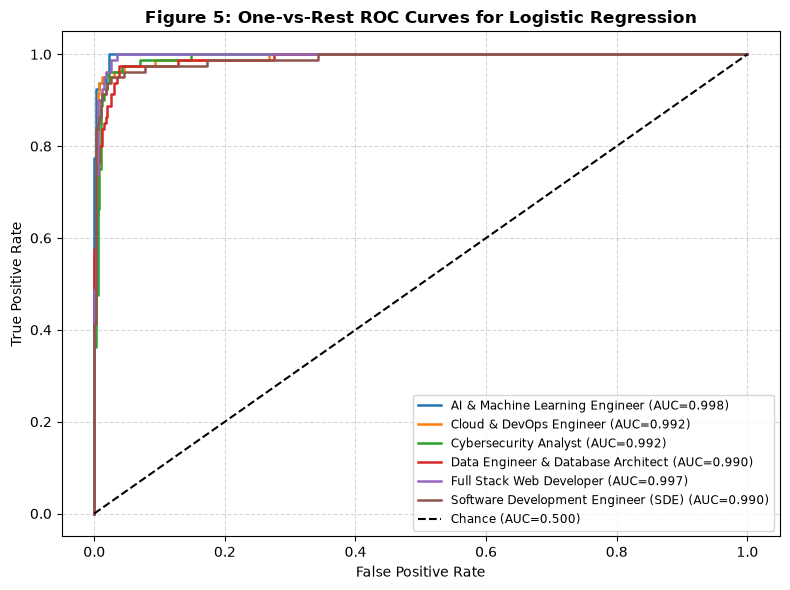

In [12]:
# Figure 5: Multi-Class ROC Curves (One-vs-Rest)
plt.figure(figsize=(8, 6))
champ_probs = probs_dict['Logistic Regression']
for i, cname in enumerate(class_names):
    y_binary = (y_test == i).astype(int)
    fpr, tpr, _ = roc_curve(y_binary, champ_probs[:, i])
    cls_auc = roc_auc_score(y_binary, champ_probs[:, i])
    plt.plot(fpr, tpr, label=f'{cname} (AUC={cls_auc:.3f})', linewidth=1.8)
plt.plot([0, 1], [0, 1], 'k--', label='Chance (AUC=0.500)')
plt.title('Figure 5: One-vs-Rest ROC Curves for Logistic Regression', fontsize=12, fontweight='bold')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right', fontsize=8.5)
plt.tight_layout()
plt.show()

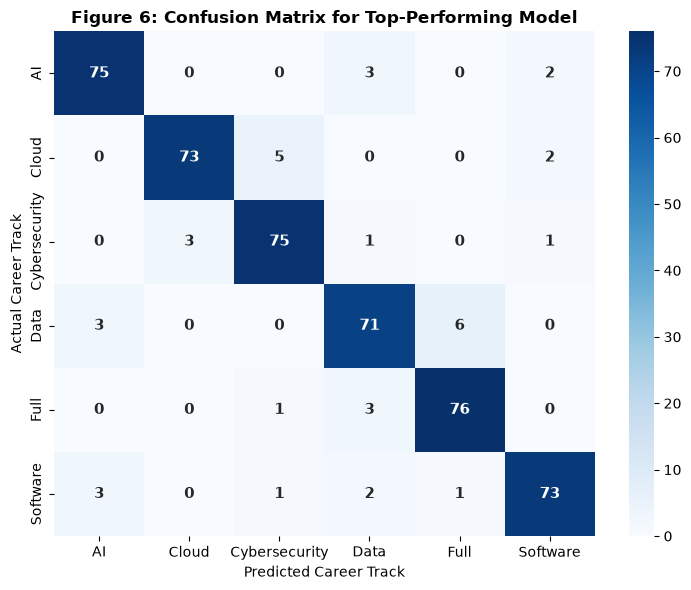

In [13]:
# Figure 6: Confusion Matrix
cm = confusion_matrix(y_test, preds_dict['Logistic Regression'])
plt.figure(figsize=(7.5, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[c.split(' ')[0] for c in class_names],
            yticklabels=[c.split(' ')[0] for c in class_names],
            annot_kws={'size': 11, 'weight': 'bold'})
plt.title('Figure 6: Confusion Matrix for Top-Performing Model', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Career Track')
plt.ylabel('Actual Career Track')
plt.tight_layout()
plt.show()

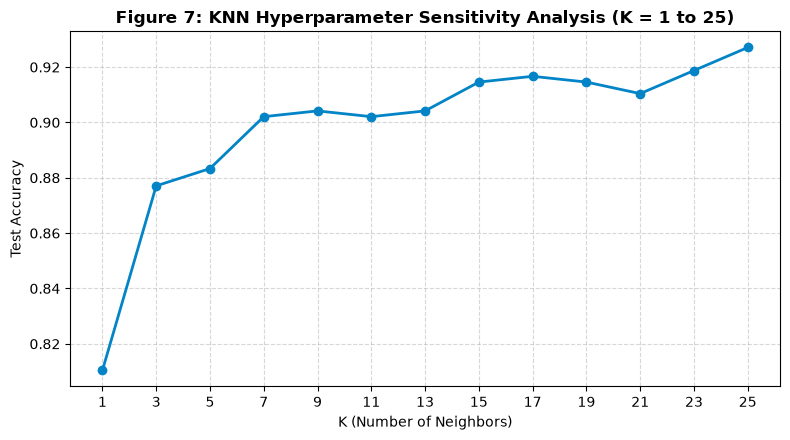

In [14]:
# Figure 7: KNN Parameter Sensitivity (K=1 to 25)
k_vals = list(range(1, 26, 2))
k_accs = []
sc = StandardScaler()
X_tr_sc = sc.fit_transform(X_train)
X_te_sc = sc.transform(X_test)
for k in k_vals:
    knn_clf = KNeighborsClassifier(n_neighbors=k)
    knn_clf.fit(X_tr_sc, y_train)
    k_accs.append(accuracy_score(y_test, knn_clf.predict(X_te_sc)))

plt.figure(figsize=(8, 4.5))
plt.plot(k_vals, k_accs, marker='o', color='#0284c7', linewidth=2)
plt.title('Figure 7: KNN Hyperparameter Sensitivity Analysis (K = 1 to 25)', fontsize=12, fontweight='bold')
plt.xlabel('K (Number of Neighbors)')
plt.ylabel('Test Accuracy')
plt.xticks(k_vals)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

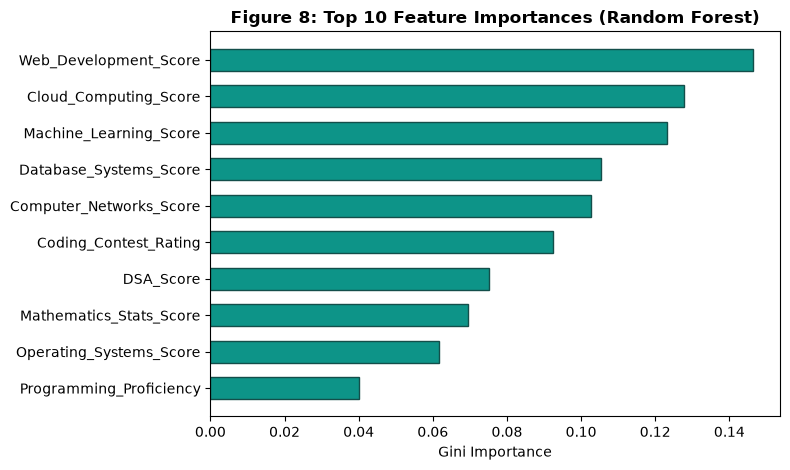

In [15]:
# Figure 8: Top 10 Feature Importances from Random Forest
rf_clf = models['Random Forest']
feat_imp = pd.DataFrame({'Feature': X.columns, 'Importance': rf_clf.feature_importances_})
top10_feats = feat_imp.sort_values('Importance', ascending=True).tail(10)

plt.figure(figsize=(8, 4.8))
plt.barh(top10_feats['Feature'], top10_feats['Importance'], color='#0d9488', edgecolor='#134e4a', height=0.6)
plt.title('Figure 8: Top 10 Feature Importances (Random Forest)', fontsize=12, fontweight='bold')
plt.xlabel('Gini Importance')
plt.tight_layout()
plt.show()

## 8. AI-Based Skill Gap Analysis & Inference Engine Demonstration

The system takes a candidate student profile, predicts the recommended career track with probability confidence, and calculates the **Skill Gap Index (SGI)** across technical competencies relative to the 75th percentile benchmark of that career track.

In [16]:
skill_features = [
    'Programming_Proficiency', 'DSA_Score', 'Operating_Systems_Score',
    'Computer_Networks_Score', 'Database_Systems_Score', 'Machine_Learning_Score',
    'Web_Development_Score', 'Cloud_Computing_Score', 'Mathematics_Stats_Score'
]

benchmarks = df.groupby('Recommended_Career')[skill_features].quantile(0.75)

# Sample Student Profile
student_sample = pd.DataFrame([{
    'CGPA': 8.1,
    'Programming_Proficiency': 78.5,
    'DSA_Score': 74.0,
    'Operating_Systems_Score': 68.0,
    'Computer_Networks_Score': 62.0,
    'Database_Systems_Score': 66.0,
    'Machine_Learning_Score': 88.5,
    'Web_Development_Score': 58.0,
    'Cloud_Computing_Score': 60.0,
    'Mathematics_Stats_Score': 84.0,
    'Coding_Contest_Rating': 1620,
    'Hackathons_Count': 3,
    'Projects_Completed': 4,
    'Certifications_Count': 2,
    'Internship_Months': 3,
    'Soft_Skills_Rating': 8.2
}])

# Inference
best_model = models['Logistic Regression']
pred_class = best_model.predict(student_sample)[0]
rec_role = le.inverse_transform([pred_class])[0]
conf_probs = best_model.predict_proba(student_sample)[0]

print(f"Recommended Career Track : {rec_role}")
print(f"Prediction Confidence    : {conf_probs[pred_class]*100:.2f}%\n")

# Skill Gap Analysis
target_bench = benchmarks.loc[rec_role]
student_vals = student_sample[skill_features].iloc[0]

gap_rows = []
for sk in skill_features:
    stu = student_vals[sk]
    bench = target_bench[sk]
    delta = stu - bench
    gap_rows.append({
        'Skill': sk.replace('_Score', '').replace('_', ' '),
        'Student_Score': stu,
        'Benchmark': bench,
        'Delta': round(delta, 1),
        'Status': 'Strength' if delta >= 0 else 'Skill Gap'
    })

gap_table = pd.DataFrame(gap_rows)
print("=" * 70)
print(f"SKILL GAP ANALYSIS MATRIX (BENCHMARK: {rec_role.upper()}):")
print("=" * 70)
print(gap_table.to_string(index=False))
print("=" * 70)

Recommended Career Track : AI & Machine Learning Engineer
Prediction Confidence    : 99.97%

SKILL GAP ANALYSIS MATRIX (BENCHMARK: AI & MACHINE LEARNING ENGINEER):
                  Skill  Student_Score  Benchmark  Delta    Status
Programming Proficiency           78.5     89.050  -10.5 Skill Gap
                    DSA           74.0     83.325   -9.3 Skill Gap
      Operating Systems           68.0     71.125   -3.1 Skill Gap
      Computer Networks           62.0     71.425   -9.4 Skill Gap
       Database Systems           66.0     71.700   -5.7 Skill Gap
       Machine Learning           88.5     90.100   -1.6 Skill Gap
        Web Development           58.0     67.225   -9.2 Skill Gap
        Cloud Computing           60.0     67.650   -7.6 Skill Gap
      Mathematics Stats           84.0     88.700   -4.7 Skill Gap


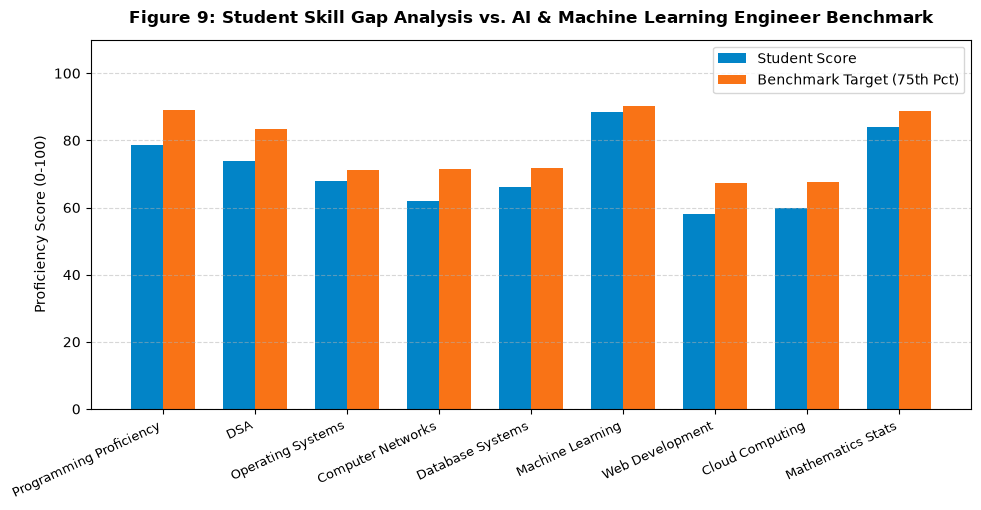

In [17]:
# Figure 9: Skill Gap Benchmark Comparison Bar Chart
x = np.arange(len(gap_table))
width = 0.35

plt.figure(figsize=(10, 5.2))
plt.bar(x - width/2, gap_table['Student_Score'], width, label='Student Score', color='#0284c7')
plt.bar(x + width/2, gap_table['Benchmark'], width, label='Benchmark Target (75th Pct)', color='#f97316')
plt.xticks(x, gap_table['Skill'], rotation=25, ha='right', fontsize=9.5)
plt.title(f'Figure 9: Student Skill Gap Analysis vs. {rec_role} Benchmark', fontsize=12, fontweight='bold', pad=12)
plt.ylabel('Proficiency Score (0-100)')
plt.ylim(0, 110)
plt.legend(loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 9. Conclusion & Actionable Learning Roadmap

### Remediation Guidance:
1. **Cloud Computing Gap (-7.6 pts)**: Complete AWS Certified Cloud Practitioner / deploy containerized projects on AWS ECS or GCP.
2. **DSA & LeetCode Gap (-9.3 pts)**: Solve 50 medium problems covering Graphs, Trees, and Dynamic Programming.
3. **Computer Networks Gap (-9.4 pts)**: Practice socket programming, TCP/IP fundamentals, and Wireshark traffic auditing.
4. **Primary Advantage**: The system empowers academic advisors and students to make empirical, data-driven decisions early in their academic journey.
---